<a href="https://colab.research.google.com/github/JasneetCreates/policy-to-impact-ai/blob/main/notebooks/01_policy_to_impact_complete_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Policy-to-Impact Intelligence System
### *From Government Policy to Ground Reality: An Evidence-Driven AI Framework for Monitoring Public Infrastructure Delivery and Detecting Emerging Service Failures*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasneetCreates/policy-to-impact-ai/blob/main/notebooks/01_policy_to_impact_complete_demo.ipynb)
**GitHub Repository:** [JasneetCreates/policy-to-impact-ai](https://github.com/JasneetCreates/policy-to-impact-ai)

---

### Project Overview & Syllabus Alignment
This project demonstrates an evidence-based Machine Learning framework for public infrastructure auditing. It cross-examines:
1. **Policy Commitments (Macro):** Budget sanctions, timelines, and road lengths.
2. **Delivery Records (Meso):** Tenders, reported completion %, contractor delays.
3. **Citizen Realities (Micro):** Grievances, accident hazard signals, and ground defect density.

#### The 12 Syllabus Machine Learning Algorithms Covered:
1. **Linear Regression:** Infrastructure delay prediction & performance evaluation ($R^2$, MSE, RMSE, MAE).
2. **Gradient Descent Convergence:** Comparative analysis of Batch, Stochastic (SGD), and Mini-Batch GD.
3. **Polynomial Regression & Learning Curves:** Modeling compounding delays; analyzing underfitting vs. overfitting.
4. **Ridge ($L_2$) & Lasso ($L_1$) Regularization:** Coefficient shrinkage & Lasso automatic feature selection.
5. **Logistic Regression:** Binary classification of high-risk discrepancy projects with 2D Decision Boundary.
6. **KNN Classification on MNIST:** Handwritten digit recognition with Confusion Matrix, Precision, and Recall.
7. **Naïve Bayes Text Classifier:** Citizen complaint classification with ROC Curve and Precision–Recall tradeoff.
8. **Support Vector Machines (SVM):** Linear, Polynomial, and RBF kernels compared with support vector counts.
9. **Decision Tree (CART Algorithm):** Visual audit tree comparing Gini Impurity vs. Entropy (Information Gain).
10. **Random Forest & Feature Importance:** MDI ranking of the top mathematical drivers of infrastructure failure.
11. **Boosting Ensemble:** AdaBoost & Gradient Boosting benchmarked against Single Tree and Random Forest.
12. **K-Means Spatial Hotspot Clustering:** Unsupervised GPS clustering of citizen complaints with Elbow & Silhouette analysis.

In [1]:
# Setup Environment and Dependencies
import sys
import os

# If running in Google Colab, clone the repository
if 'google.colab' in str(get_ipython()):
    print("Running on Google Colab! Cloning repository...")
    !git clone https://github.com/JasneetCreates/policy-to-impact-ai.git
    %cd policy-to-impact-ai
    !pip install -q -r requirements.txt
else:
    print("Running in local environment.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Inline plotting setup
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

print("Environment verified!")

Running on Google Colab! Cloning repository...
Cloning into 'policy-to-impact-ai'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 64 (delta 13), reused 60 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (64/64), 2.14 MiB | 24.64 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/policy-to-impact-ai
Environment verified!


---
## Stage 0: Multi-Tier Data Ingestion & Dataset Preparation
We load real-world inspired public infrastructure projects, delivery logs, citizen grievances, and the MNIST benchmark dataset.

In [2]:
from src.data_loader import generate_curated_datasets

df_projects, df_complaints, df_mnist = generate_curated_datasets()
print(f"Projects shape: {df_projects.shape}")
print(f"Complaints shape: {df_complaints.shape}")
print(f"MNIST sample shape: {df_mnist.shape}")

df_projects[['project_id', 'city', 'project_name', 'sanctioned_budget_cr', 'length_km', 'delay_months', 'is_discrepancy']].head()

[OK] Generated 60 infrastructure project records.
[OK] Generated 1105 citizen complaints across 3 categories.
[OK] Generated MNIST benchmark dataset with 1797 samples and 64 pixel features.
Projects shape: (60, 23)
Complaints shape: (1105, 9)
MNIST sample shape: (1797, 65)


,project_id,city,project_name,sanctioned_budget_cr,length_km,delay_months,is_discrepancy
0,PROJ-INFRA-101,Pune,Pune High-Capacity Mass Transit Road Upgradati...,1818.84,62.4,9,1
1,PROJ-INFRA-102,Ludhiana,Krishna Mandir to Ishmeet Chowk Corridor Impro...,44.72,9.1,5,0
2,PROJ-INFRA-103,Bengaluru,Outer Ring Road Junction & Flyover Decongestio...,857.05,28.6,10,0
3,PROJ-INFRA-104,Ludhiana,Chandigarh-Ludhiana Highway Smart Corridor Wid...,668.38,48.5,8,0
4,PROJ-INFRA-105,Pune,Shivaji Nagar to Hinjewadi Arterial Road Stren...,412.04,23.9,7,1


---
## 1. Linear Regression (Syllabus Item 1)
Evaluating project delay predictions using $R^2$, MSE, RMSE, and MAE.

In [3]:
from src.stage1_regression import load_regression_data, evaluate_linear_regression

X, y, df = load_regression_data()
eval_res = evaluate_linear_regression(X, y)


1. LINEAR REGRESSION PERFORMANCE METRICS
R-squared (R2) Score : -0.2834
Mean Squared Error (MSE) : 4.7686
Root Mean Squared Error (RMSE) : 2.1837
Mean Absolute Error (MAE) : 1.7609
Learned Feature Coefficients:
  - sanctioned_budget_cr      : -0.6105
  - length_km                 : -2.8452
  - num_major_junctions       : +3.6662
  - past_contractor_delays    : +1.1700
  - contractor_experience_yrs : -0.0123
  - Intercept                 : +5.6000


---
## 2. Gradient Descent Convergence: Batch vs. SGD vs. Mini-Batch (Syllabus Item 2)
Comparing the convergence behavior and stability of Batch, Stochastic, and Mini-Batch Gradient Descent from scratch.


2. GRADIENT DESCENT CONVERGENCE COMPARISON
Final Batch GD Loss       : 3.7021 (Smooth, monotonic convergence)
Final Stochastic GD Loss  : 3.4509 (Rapid early drop, mild oscillation)
Final Mini-Batch GD Loss  : 3.4497 (Optimal balance of speed & stability)
-> Saved convergence plot to: outputs/figures/01_gradient_descent_convergence.png


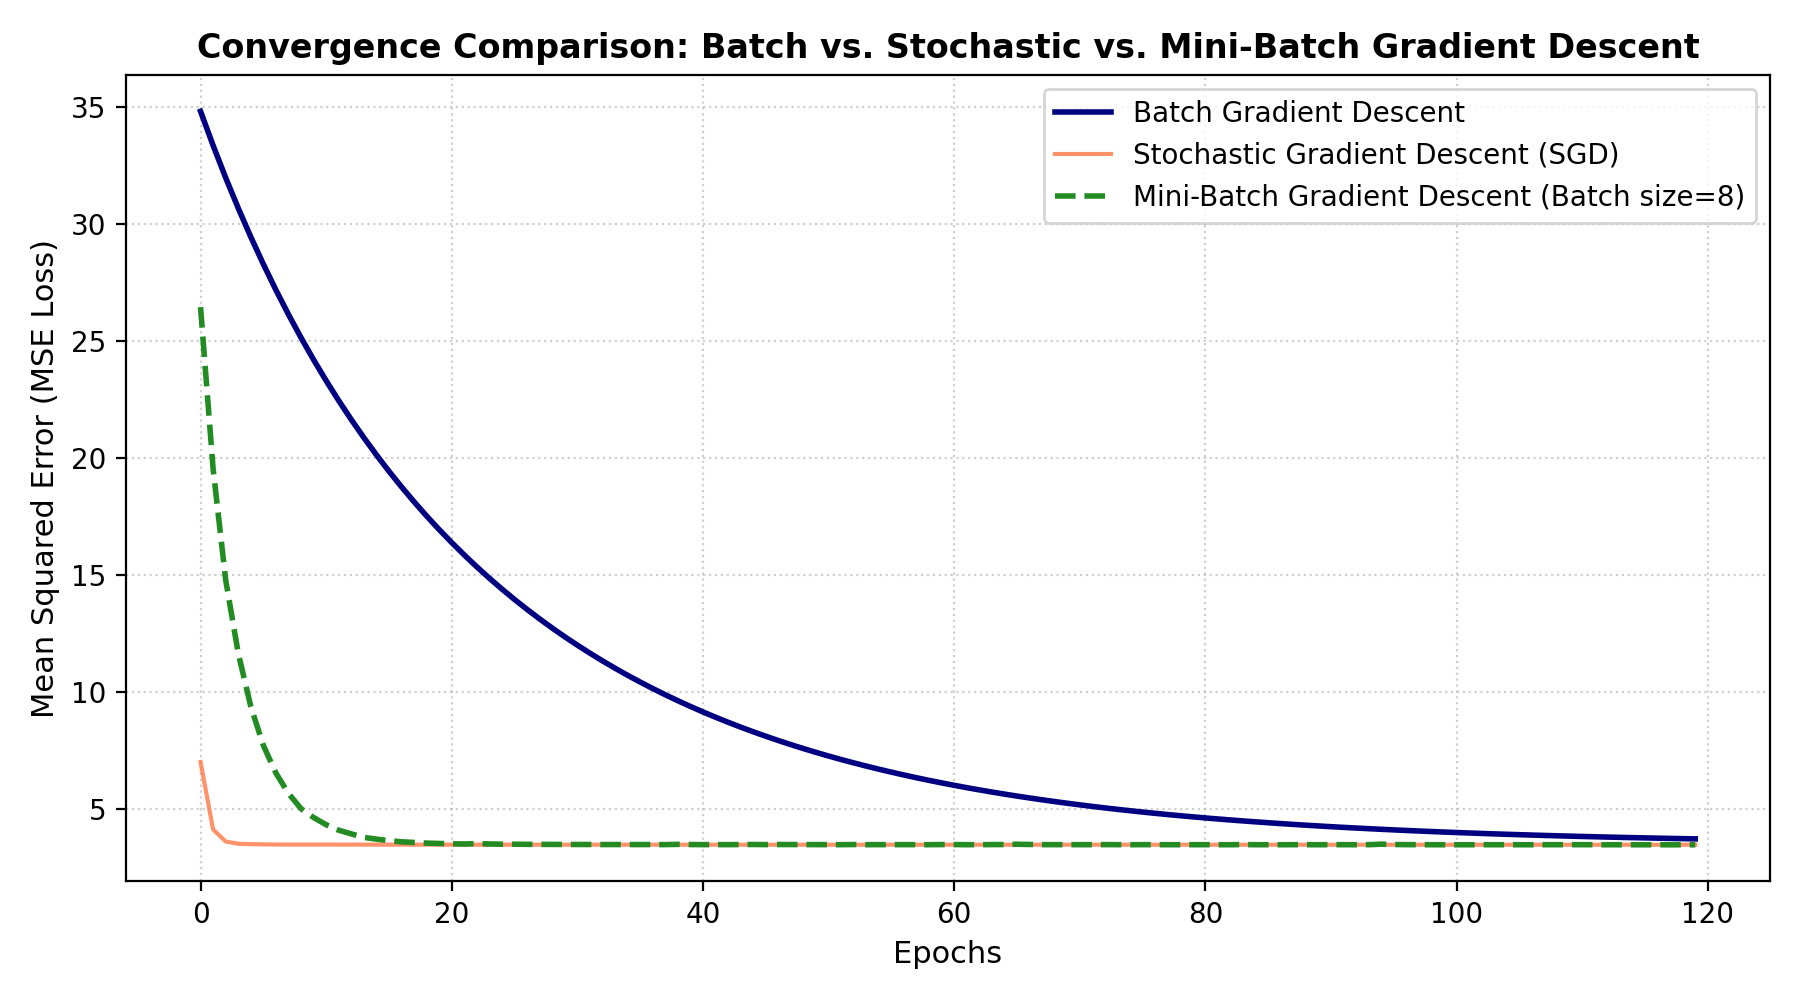

In [4]:
from src.stage1_regression import compare_gradient_descent

bgd, sgd, mbgd = compare_gradient_descent(X, y, n_epochs=120, lr=0.01)

# Display the generated figure
from IPython.display import Image
Image(filename='outputs/figures/01_gradient_descent_convergence.png')

---
## 3. Polynomial Regression & Learning Curves (Syllabus Item 3)
Analyzing underfitting (Degree 1) vs. optimal fit (Degree 2) vs. overfitting (Degree 5) using learning curves.


3. POLYNOMIAL REGRESSION & LEARNING CURVE ANALYSIS
Degree 1 (Linear)    : Underfits non-linear cost escalations.
Degree 2 (Quadratic) : Captures compounding infrastructure overhead without excessive variance.
Degree 5 (High Deg)  : High variance, risks memorizing outliers.
-> Saved polynomial & learning curves plot to: outputs/figures/02_polynomial_regression_learning_curves.png


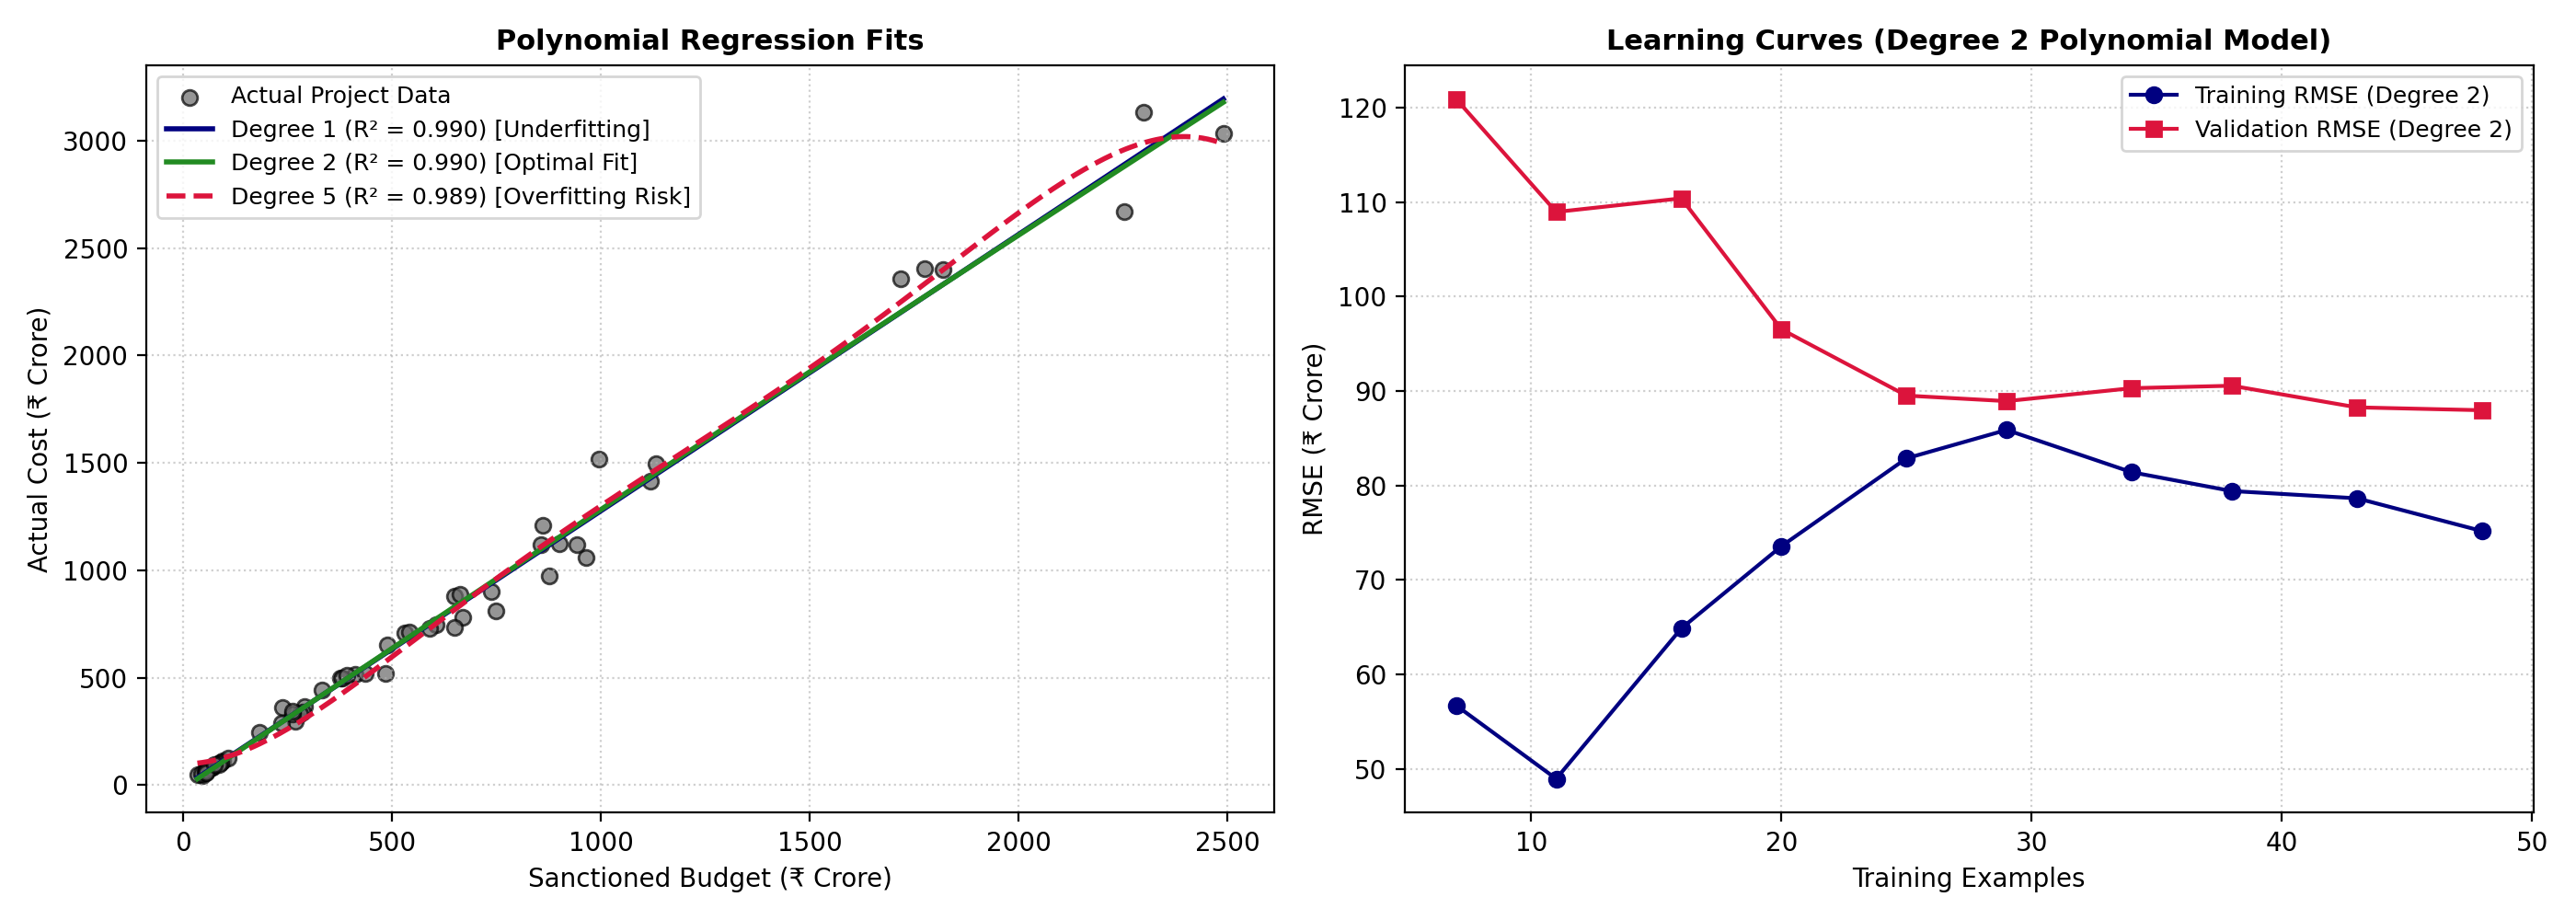

In [5]:
from src.stage1_regression import analyze_polynomial_and_learning_curves

poly_models = analyze_polynomial_and_learning_curves(df)
Image(filename='outputs/figures/02_polynomial_regression_learning_curves.png')

---
## 4. Ridge & Lasso Regularization (Syllabus Item 4)
Evaluating coefficient shrinkage ($L_2$) and automatic feature selection ($L_1$) across regularization strengths $lpha$.


4. RIDGE & LASSO REGULARIZATION EFFECT
Ridge (alpha=1.0) Test RMSE : 2.2340 (Shrinks coefficients smoothly towards 0)
Lasso (alpha=0.1) Test RMSE : 2.1981 (Drives irrelevant features exactly to 0)
Lasso Sparsity (Feature selection):
  - sanctioned_budget_cr      : -0.0000 [Eliminated (Zero)]
  - length_km                 : +0.0000 [Eliminated (Zero)]
  - num_major_junctions       : +0.1968 [Active]
  - past_contractor_delays    : +1.0877 [Active]
  - contractor_experience_yrs : -0.0011 [Active]
-> Saved Ridge & Lasso regularization path plot to: outputs/figures/03_ridge_lasso_regularization.png


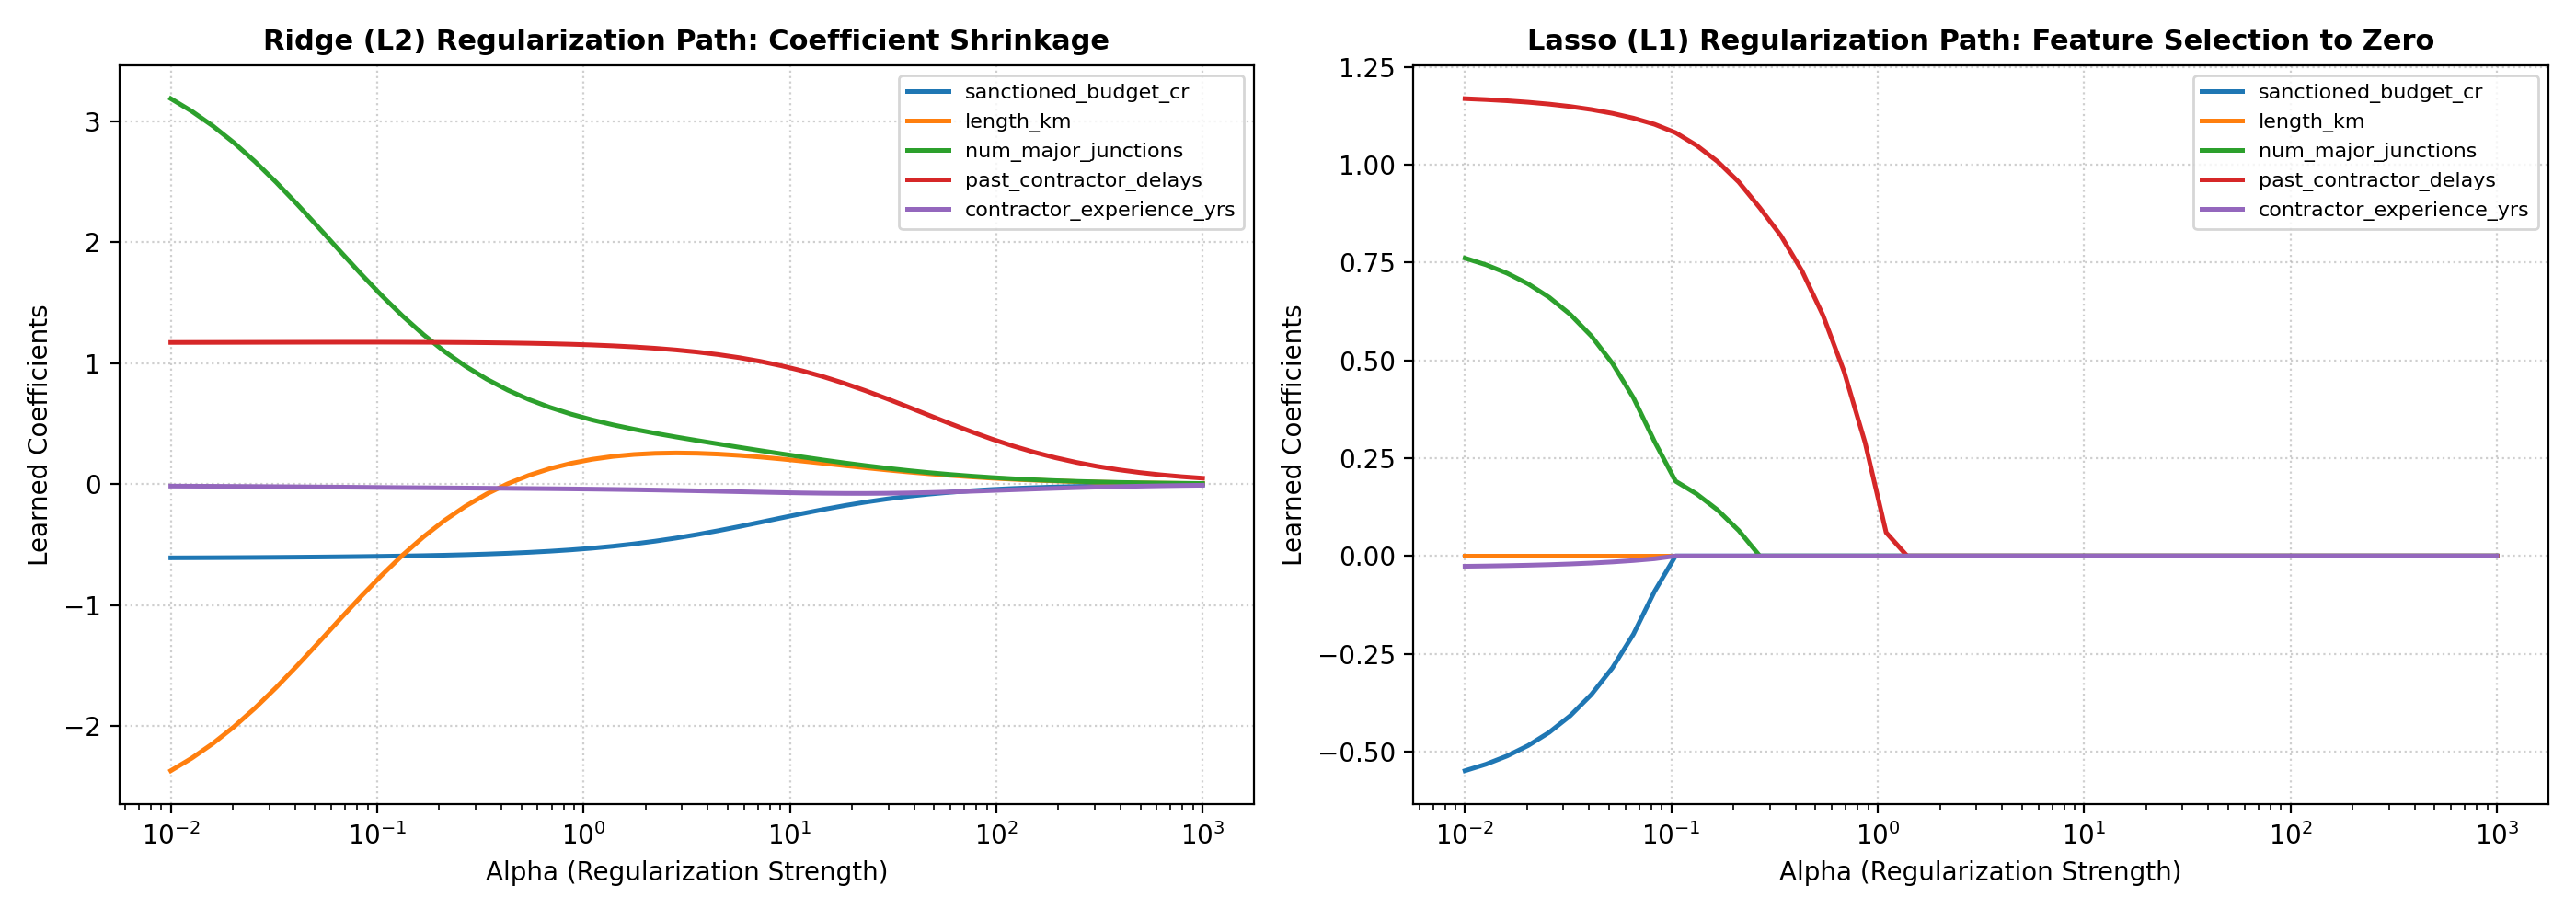

In [6]:
from src.stage1_regression import analyze_ridge_and_lasso

best_ridge, best_lasso = analyze_ridge_and_lasso(X, y)
Image(filename='outputs/figures/03_ridge_lasso_regularization.png')

---
## 5. Logistic Regression: Binary Discrepancy Classification & Decision Boundary (Syllabus Item 5)
Classifying high-risk projects and plotting the 2D decision boundary contour.


5. LOGISTIC REGRESSION: BINARY DISCREPANCY CLASSIFICATION
Accuracy Score: 83.33%
Confusion Matrix:
  [TN: 9  FP: 2]
  [FN: 1  TP: 6]

Classification Report:
                 precision    recall  f1-score   support

     Normal (0)       0.90      0.82      0.86        11
Discrepancy (1)       0.75      0.86      0.80         7

       accuracy                           0.83        18
      macro avg       0.82      0.84      0.83        18
   weighted avg       0.84      0.83      0.83        18

-> Saved Logistic Regression decision boundary plot to: outputs/figures/04_logistic_regression_decision_boundary.png


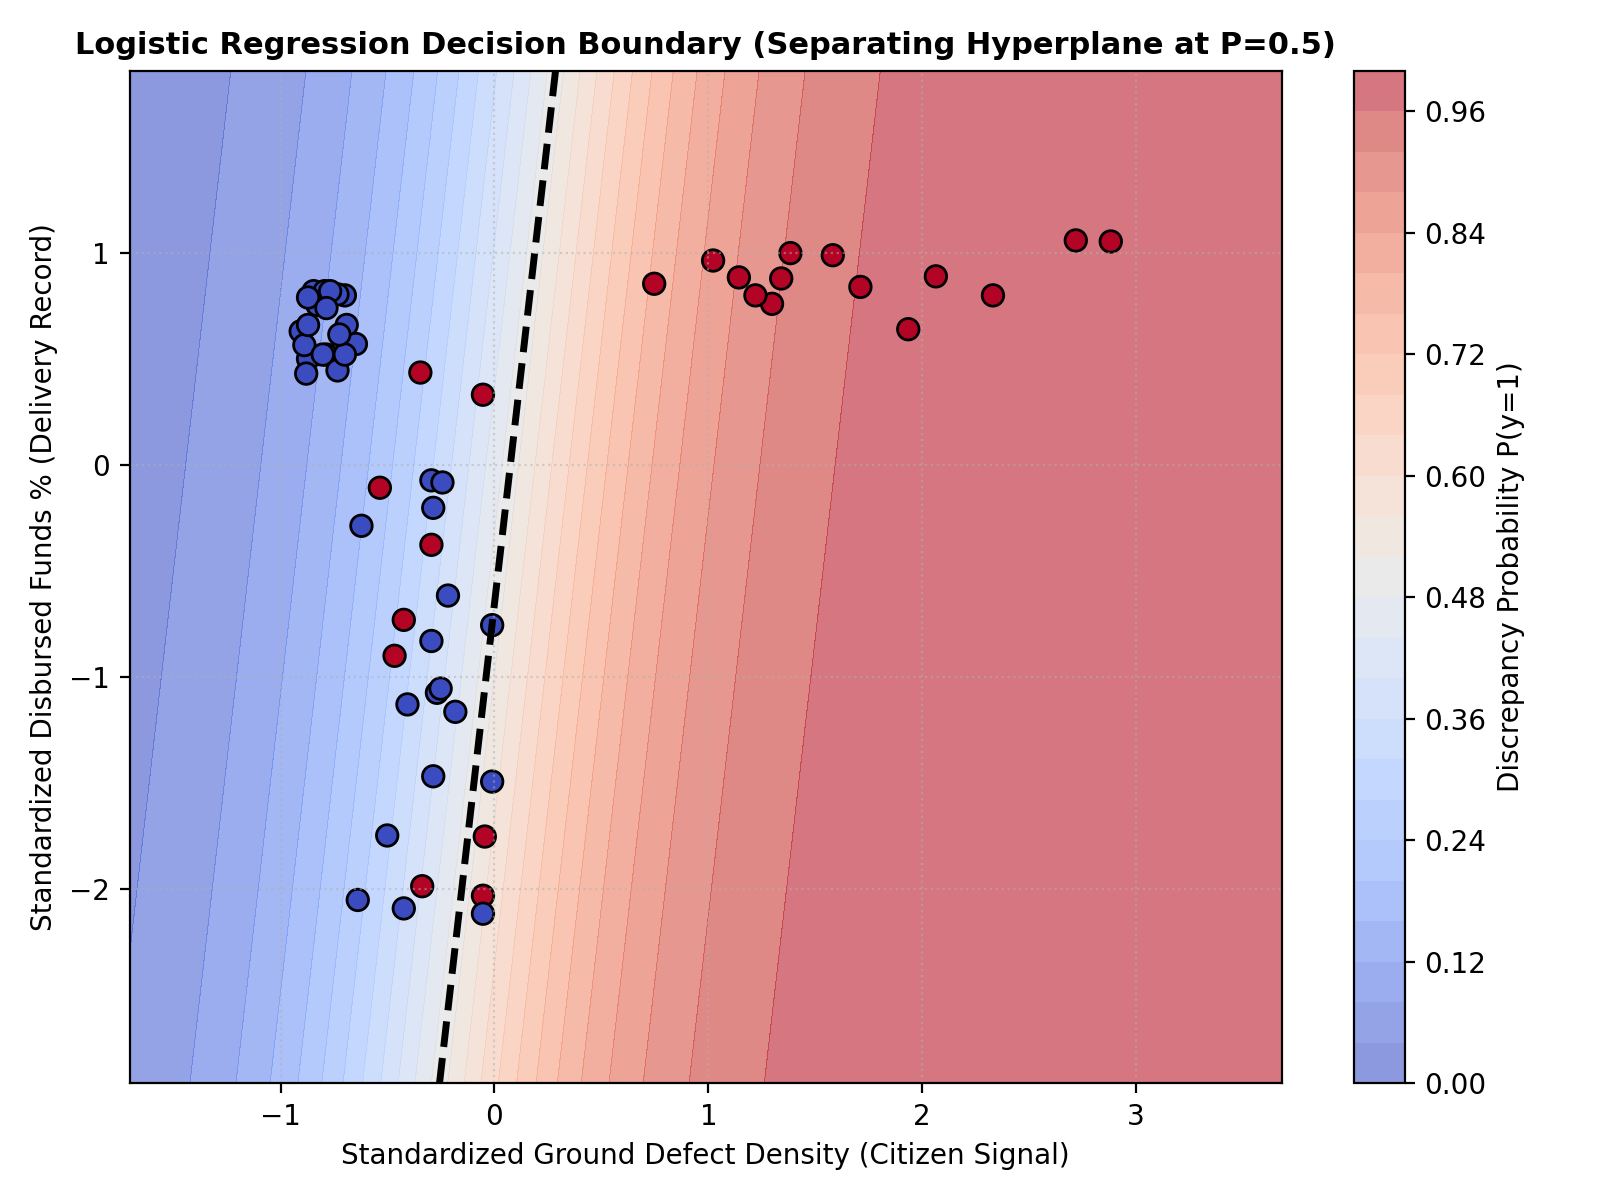

In [7]:
from src.stage2_citizen_nlp import evaluate_logistic_regression

clf_log, scaler = evaluate_logistic_regression()
Image(filename='outputs/figures/04_logistic_regression_decision_boundary.png')

---
## 7. Naïve Bayes Classifier on Citizen Grievances (Syllabus Item 7)
Classifying unstructured complaints and analyzing the ROC Curve and Precision–Recall Tradeoff.


7. NAIVE BAYES CLASSIFIER ON CITIZEN COMPLAINTS
Accuracy: 58.48%
Area Under ROC Curve (ROC-AUC) : 0.7068
Average Precision (PR-AUC)     : 0.8879

Classification Report:
                       precision    recall  f1-score   support

Routine Complaint (0)       0.34      0.66      0.45        71
    Urgent Hazard (1)       0.83      0.56      0.67       206

             accuracy                           0.58       277
            macro avg       0.58      0.61      0.56       277
         weighted avg       0.70      0.58      0.61       277

-> Saved Naive Bayes ROC and Precision-Recall plot to: outputs/figures/05_naive_bayes_roc_precision_recall.png


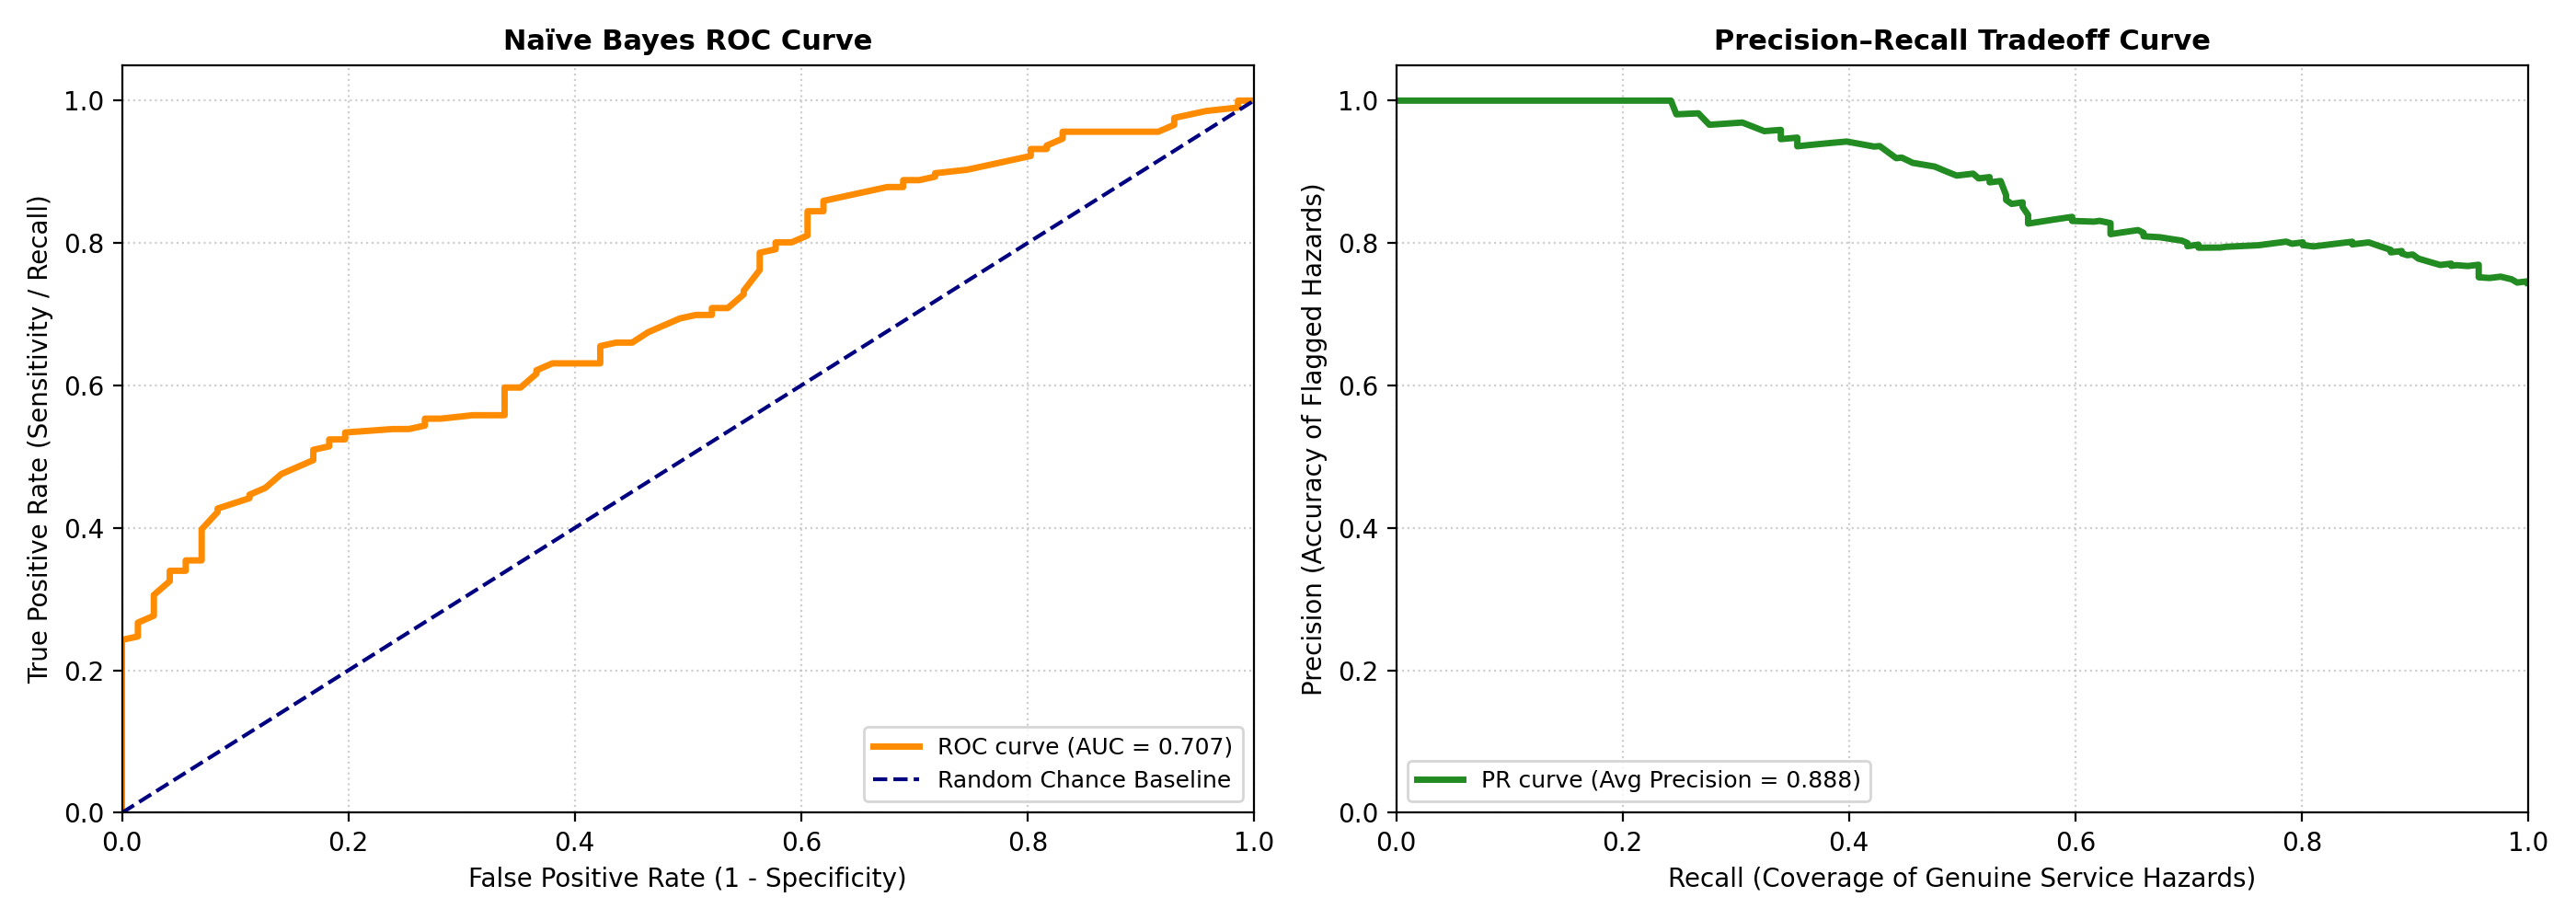

In [8]:
from src.stage2_citizen_nlp import evaluate_naive_bayes

nb_model, vectorizer = evaluate_naive_bayes()
Image(filename='outputs/figures/05_naive_bayes_roc_precision_recall.png')

---
## 12. K-Means Spatial Hotspot Clustering (Syllabus Item 12)
Discovering geographic failure hotspots using the Elbow Method and Silhouette Analysis.


12. K-MEANS SPATIAL HOTSPOT CLUSTERING
Evaluated k from 2 to 8
  k=2 -> Inertia: 0.674449 | Silhouette Score: 0.4494
  k=3 -> Inertia: 0.356023 | Silhouette Score: 0.5245
  k=4 -> Inertia: 0.242799 | Silhouette Score: 0.5651
  k=5 -> Inertia: 0.155856 | Silhouette Score: 0.6075
  k=6 -> Inertia: 0.110549 | Silhouette Score: 0.6041
  k=7 -> Inertia: 0.084794 | Silhouette Score: 0.6262
  k=8 -> Inertia: 0.065246 | Silhouette Score: 0.5727
Optimal Cluster Count (max Silhouette): k = 7
-> Saved K-Means hotspot & evaluation plot to: outputs/figures/06_kmeans_hotspots_elbow_silhouette.png


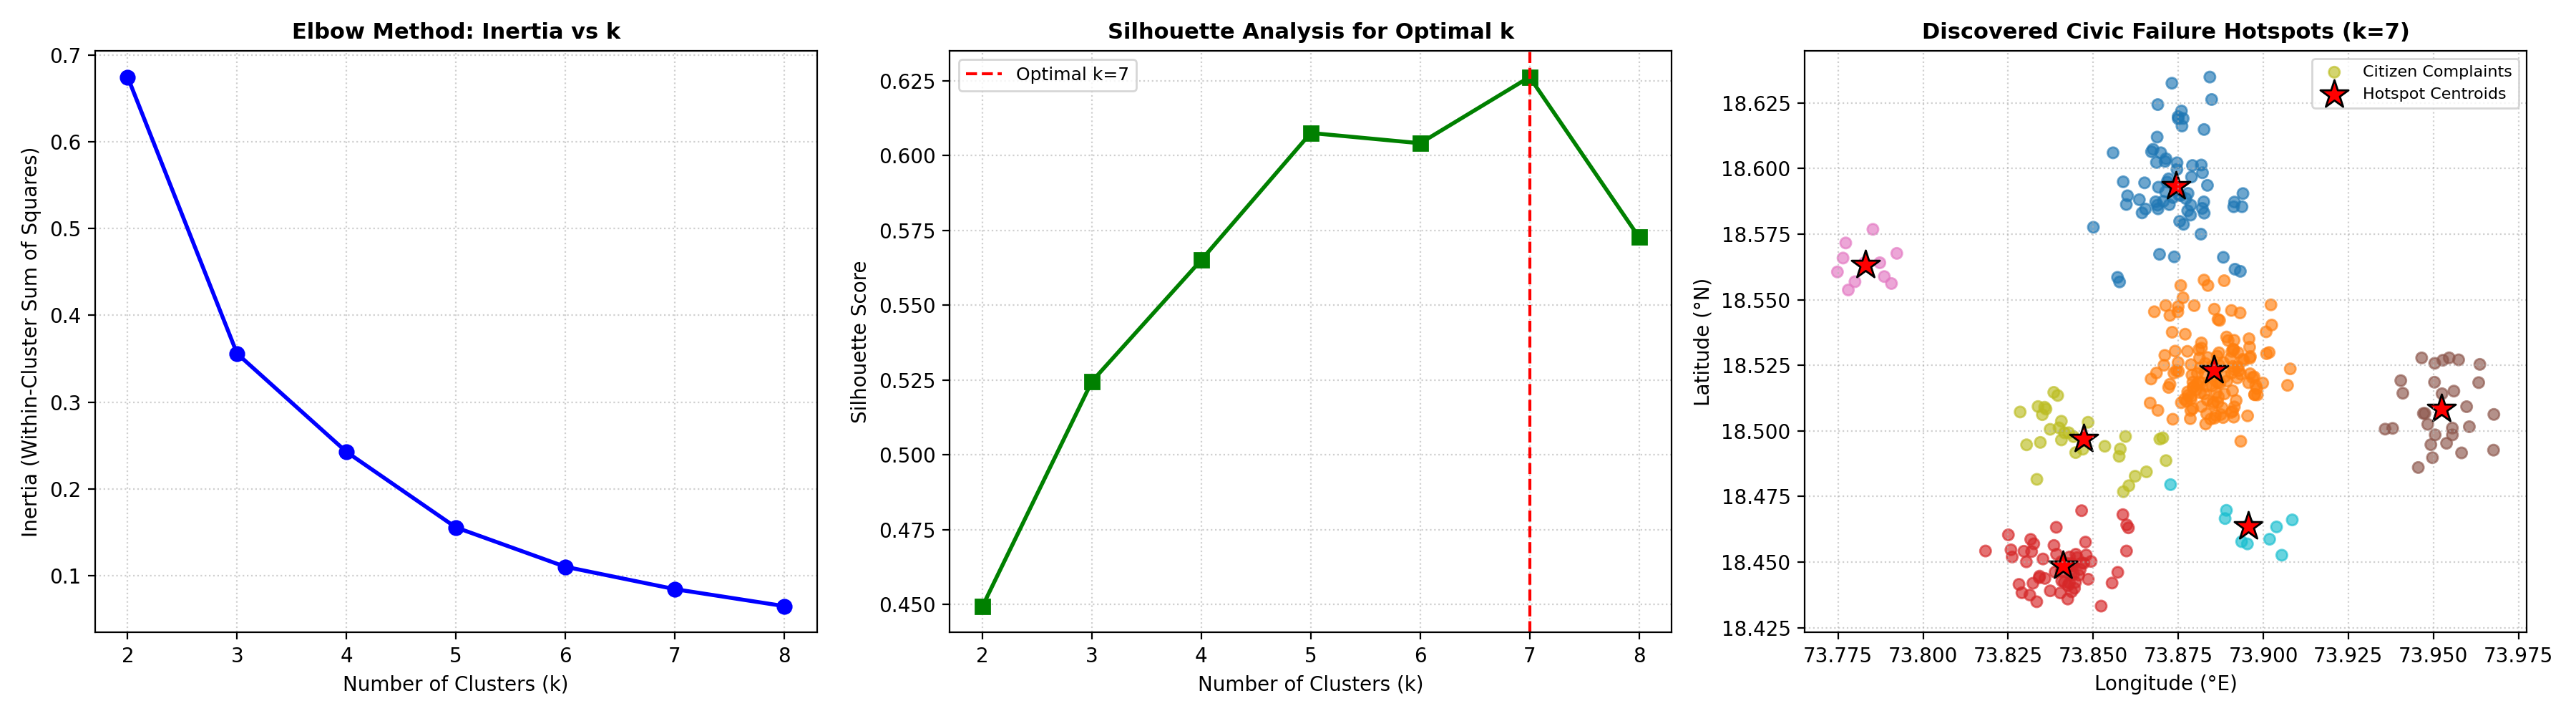

In [9]:
from src.stage2_citizen_nlp import evaluate_kmeans_clustering

final_kmeans, optimal_k = evaluate_kmeans_clustering()
Image(filename='outputs/figures/06_kmeans_hotspots_elbow_silhouette.png')

---
## 6. KNN Classification on the MNIST Dataset (Syllabus Item 6)
Evaluating handwritten digit recognition across neighborhood sizes ($k$) with Confusion Matrix, Precision, and Recall.


6. KNN CLASSIFICATION ON MNIST DATASET
Dataset Size: 1797 images (8x8 grayscale = 64 features)
Optimal k: 1 with Test Accuracy: 98.44%

Accuracy across neighborhood sizes (k):
  k =  1 -> Accuracy: 98.44%
  k =  3 -> Accuracy: 98.44%
  k =  5 -> Accuracy: 98.44%
  k =  7 -> Accuracy: 98.00%
  k =  9 -> Accuracy: 97.56%
  k = 11 -> Accuracy: 97.78%
  k = 15 -> Accuracy: 96.89%

Detailed Per-Digit Classification Report (Precision, Recall, F1):
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9388    1.0000    0.9684        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     0.9783    1.0000    0.9890        45
           5     1.0000    0.9783    0.9890        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    1.0000    1.0000        45
           8     0.9750    0.9070    0.9398        43
           9

/content/policy-to-impact-ai/src/mnist_knn_benchmark.py:141: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.67, 1.0])


-> Saved KNN MNIST evaluation and confusion matrix plot to: outputs/figures/07_knn_mnist_confusion_matrix.png


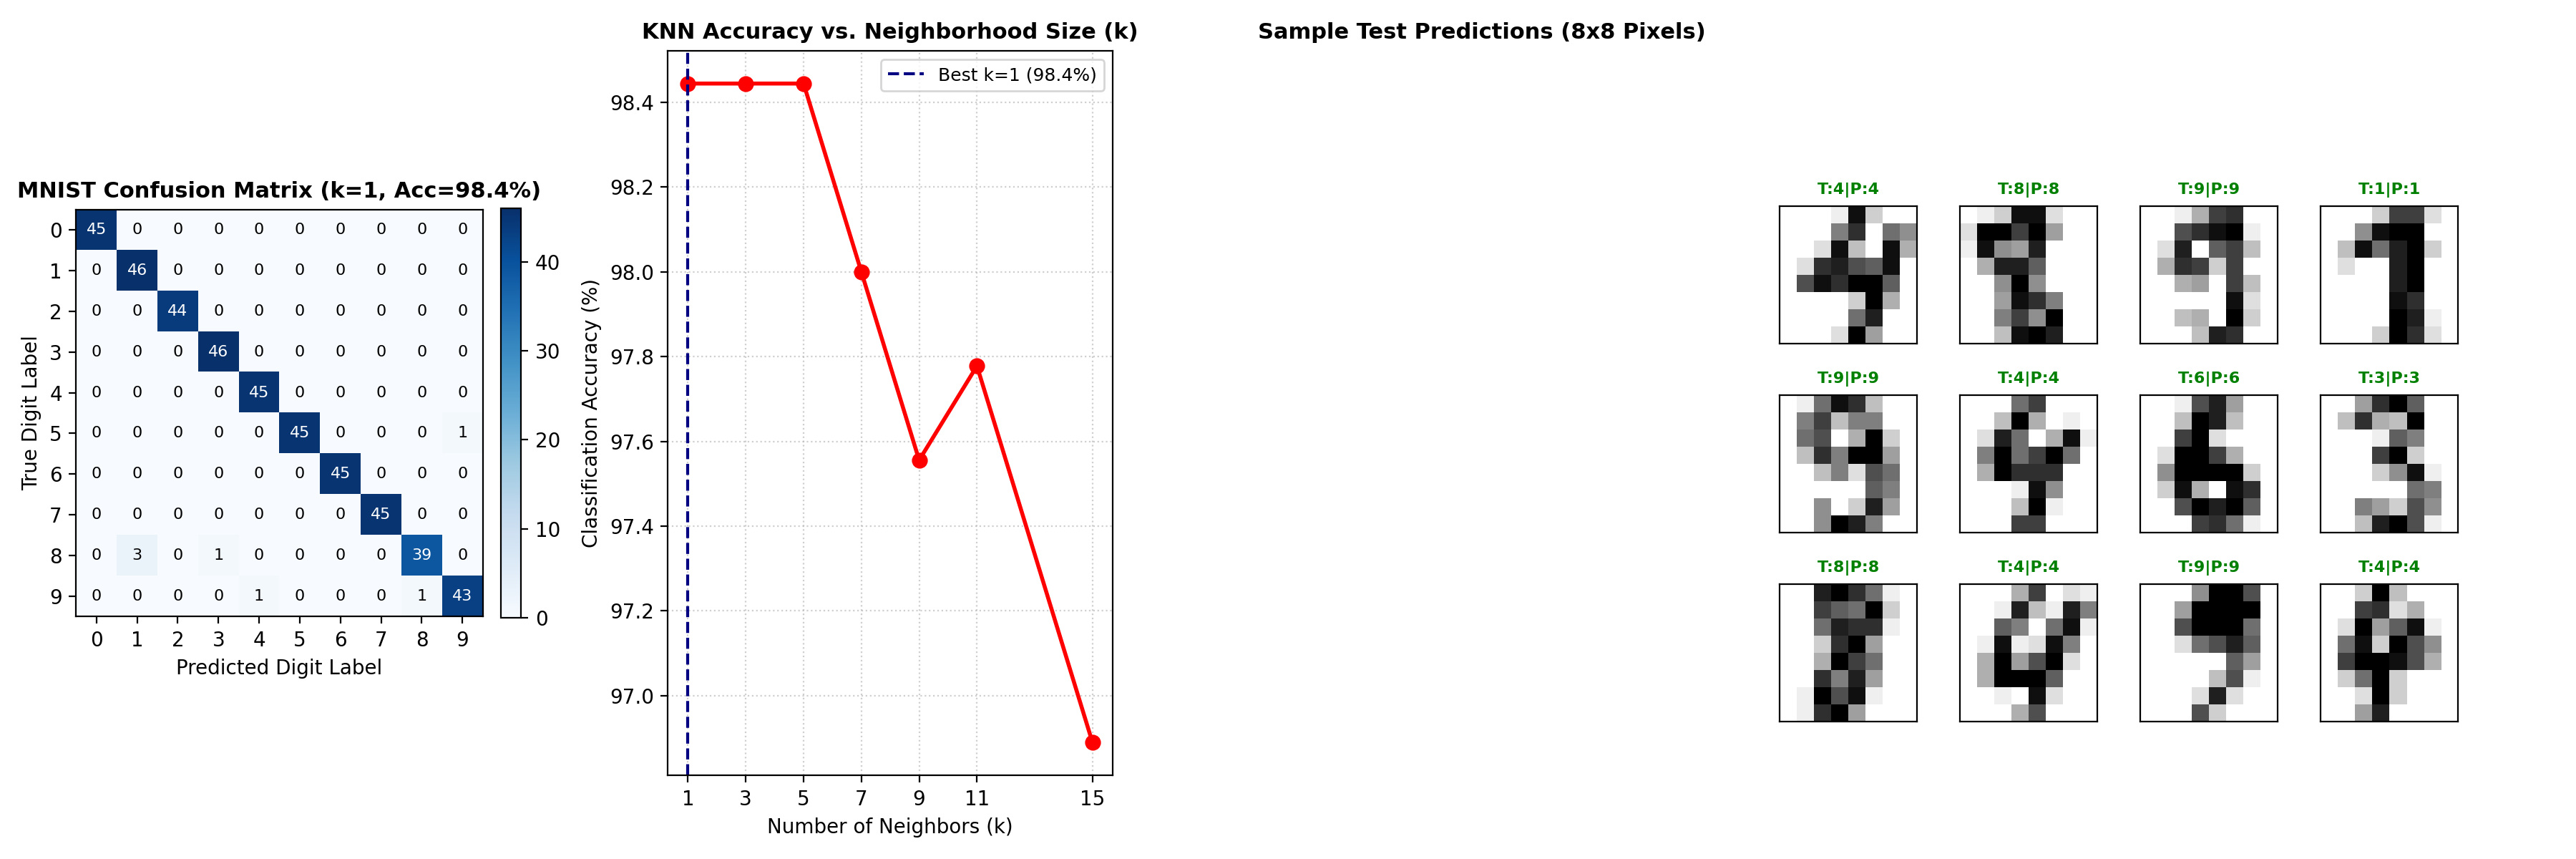

In [10]:
from src.mnist_knn_benchmark import evaluate_knn_on_mnist

final_knn, cm, report = evaluate_knn_on_mnist()
Image(filename='outputs/figures/07_knn_mnist_confusion_matrix.png')

---
## 8. Linear & Non-Linear SVM: Polynomial & RBF Kernels (Syllabus Item 8)
Comparing Linear, Polynomial, and RBF kernels on project discrepancy classification.


8. SUPPORT VECTOR MACHINES: LINEAR VS NONLINEAR KERNELS
Linear SVM                -> Accuracy: 83.33% | Support Vectors: 15
Polynomial Kernel (d=3)   -> Accuracy: 88.89% | Support Vectors: 20
RBF Kernel (Gaussian)     -> Accuracy: 100.00% | Support Vectors: 22
-> Saved SVM kernels comparison plot to: outputs/figures/08_svm_linear_poly_rbf_comparison.png


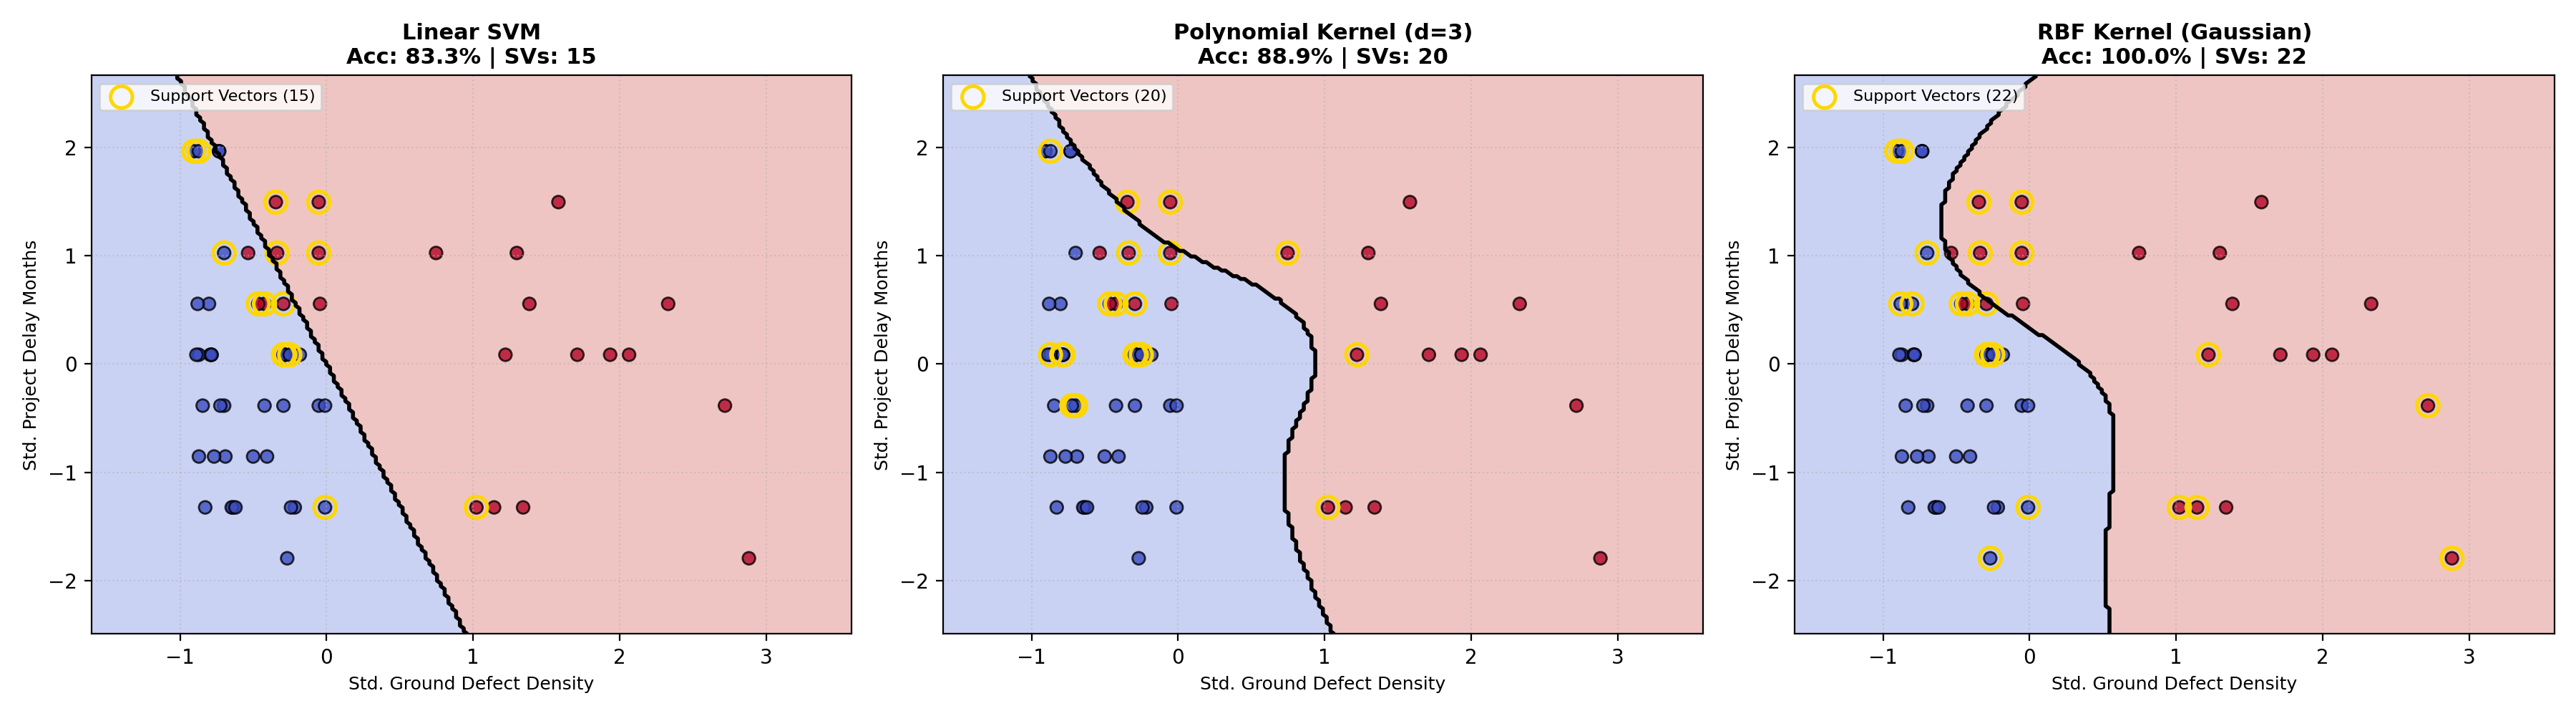

In [11]:
from src.stage3_triangulation_ml import load_triangulated_features, evaluate_svm_kernels

X_full, y_full, df_full, feature_names = load_triangulated_features()
svm_res = evaluate_svm_kernels(df_full)
Image(filename='outputs/figures/08_svm_linear_poly_rbf_comparison.png')

---
## 9. Decision Tree (CART): Gini Impurity vs. Entropy (Syllabus Item 9)
Constructing interpretable decision trees for government auditors and comparing splitting criteria.


9. DECISION TREE (CART): GINI IMPURITY VS ENTROPY
Gini Impurity Tree Accuracy  : 94.44% (Tree depth: 3, Leaves: 4)
Entropy Tree Accuracy        : 94.44% (Tree depth: 3, Leaves: 4)
-> Saved Decision Tree Gini vs Entropy visualization to: outputs/figures/09_decision_tree_cart_gini_vs_entropy.png


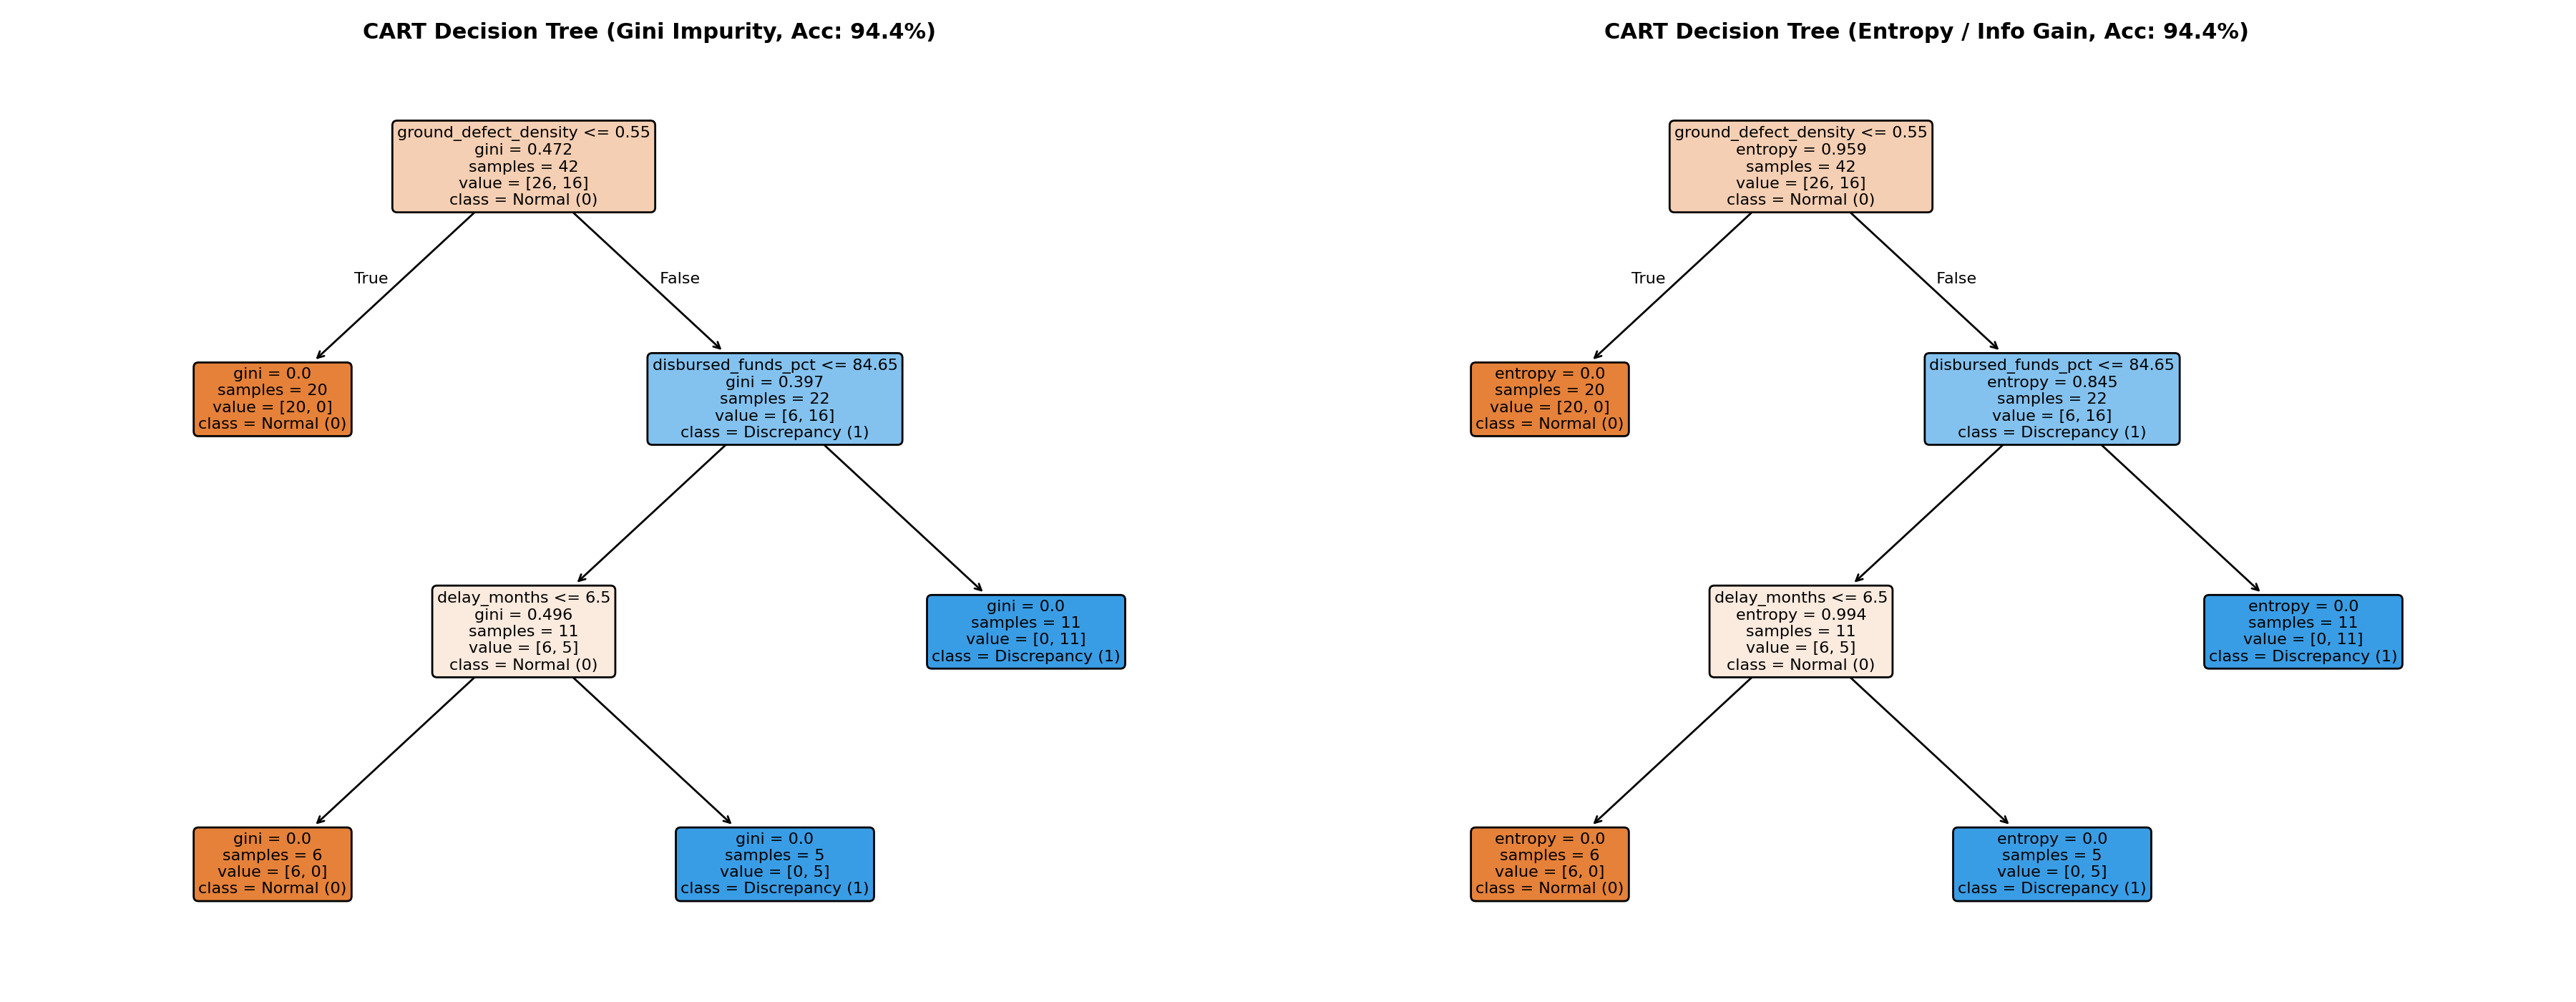

In [12]:
from src.stage3_triangulation_ml import evaluate_decision_tree

tree_g, tree_e = evaluate_decision_tree(X_full, y_full, feature_names)
Image(filename='outputs/figures/09_decision_tree_cart_gini_vs_entropy.png')

---
## 10. Random Forest & Feature Importance Ranking (Syllabus Item 10)
Measuring Out-Of-Bag score and ranking the top mathematical drivers of public service failure.


10. RANDOM FOREST & FEATURE IMPORTANCE RANKING
Random Forest Test Accuracy : 94.44%
Out-of-Bag (OOB) Score      : 90.48%

Feature Importance Ranking (Mean Decrease in Impurity):
  - ground_defect_density     : 35.73%
  - citizen_complaint_count   : 24.77%
  - delay_months              : 12.29%
  - disbursed_funds_pct       : 11.75%
  - contractor_experience_yrs : 4.28%
  - sanctioned_budget_cr      : 3.57%
  - length_km                 : 2.94%
  - past_contractor_delays    : 2.43%
  - num_major_junctions       : 2.25%
-> Saved Random Forest Feature Importance plot to: outputs/figures/10_random_forest_feature_importance.png


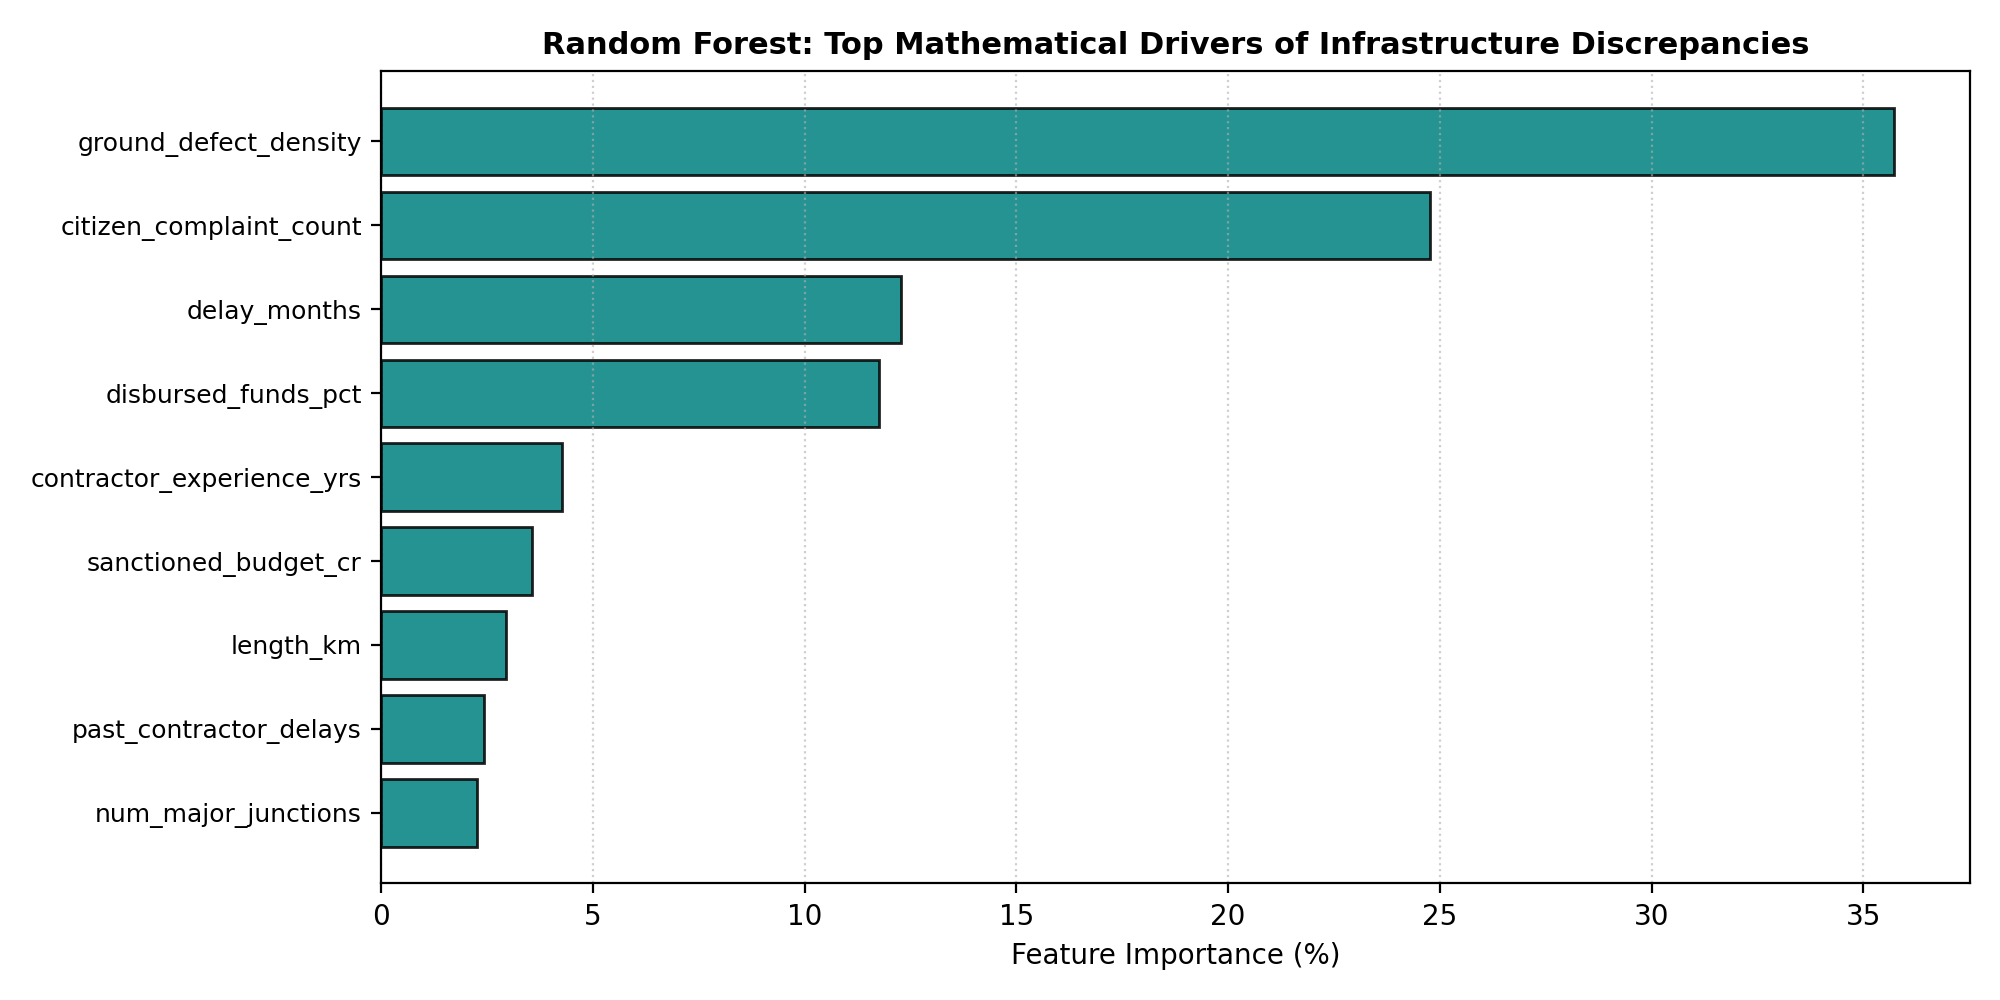

In [13]:
from src.stage3_triangulation_ml import evaluate_random_forest

rf, sorted_features, sorted_importances = evaluate_random_forest(X_full, y_full, feature_names)
Image(filename='outputs/figures/10_random_forest_feature_importance.png')

---
## 11. Boosting Technique & Ensemble Benchmark (Syllabus Item 11)
Benchmarking AdaBoost and Gradient Boosting against a single CART tree and Random Forest.


11. BOOSTING & ENSEMBLE PERFORMANCE BENCHMARK
Single CART Tree           | Acc: 94.44% | Prec: 1.000 | Rec: 0.857 | F1: 0.923 | AUC: 0.929
Random Forest (100 Trees)  | Acc: 94.44% | Prec: 1.000 | Rec: 0.857 | F1: 0.923 | AUC: 0.974
AdaBoost Classifier        | Acc: 94.44% | Prec: 1.000 | Rec: 0.857 | F1: 0.923 | AUC: 0.883
Gradient Boosting          | Acc: 94.44% | Prec: 1.000 | Rec: 0.857 | F1: 0.923 | AUC: 0.981
-> Saved Ensemble models comparison plot to: outputs/figures/11_ensemble_models_comparison.png


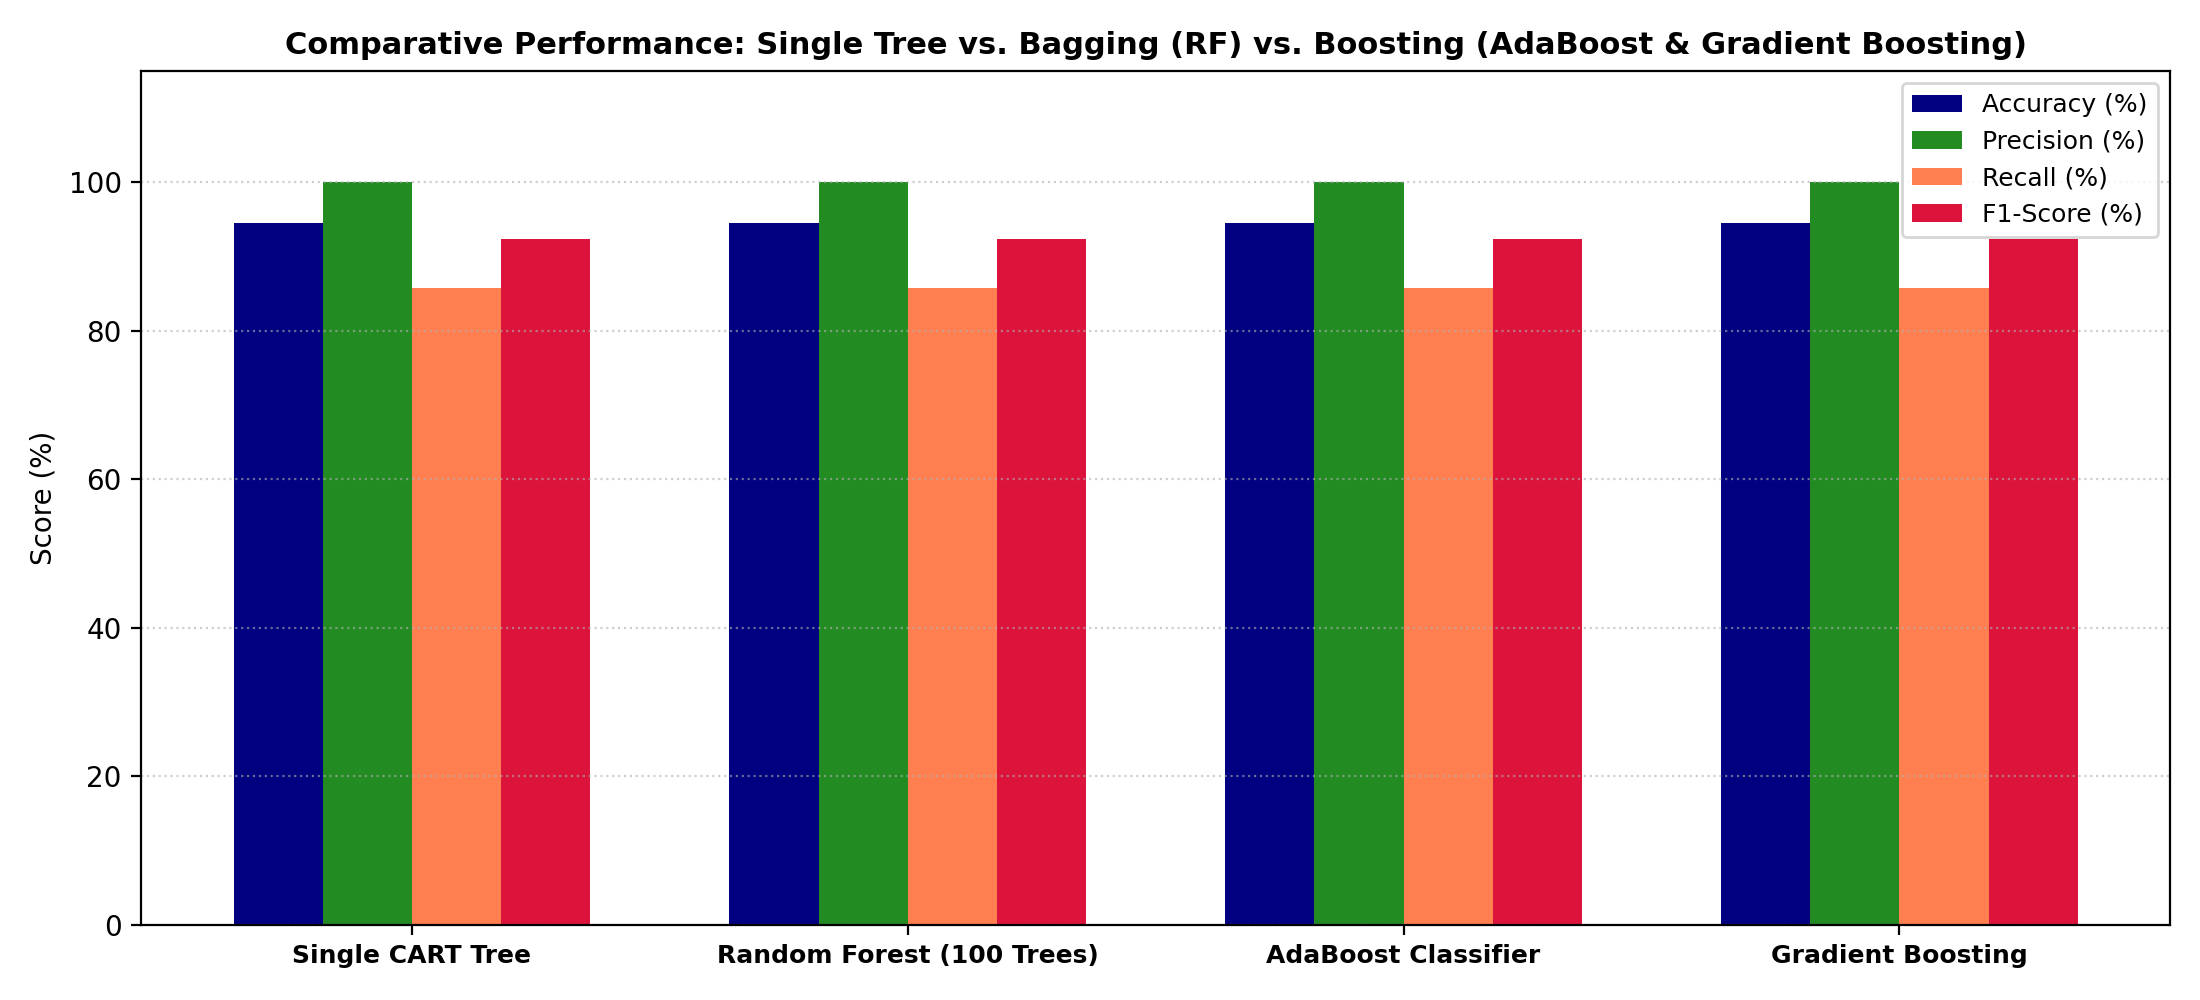

In [14]:
from src.stage3_triangulation_ml import evaluate_boosting_and_comparison

df_metrics = evaluate_boosting_and_comparison(X_full, y_full, feature_names)
Image(filename='outputs/figures/11_ensemble_models_comparison.png')

---
## Final Synthesis: Automated Triangulation Intelligence Dossier
The AI framework connects policy commitments, delivery records, and citizen complaints to flag discrepancy cases requiring field audits.

In [15]:
from main import generate_final_intelligence_dossier

generate_final_intelligence_dossier()


FINAL AUDIT DOSSIER: FLAGGED INFRASTRUCTURE CORRIDORS
Total Monitored Projects : 60
Total Discrepancies Flagged : 23 (38.3% of portfolio)
--------------------------------------------------------------------------------
Project ID : PROJ-INFRA-101 | City: Pune
Title      : Pune High-Capacity Mass Transit Road Upgradation Phase 1
Budget     : Sanctioned: ₹1818.84 Cr | Disbursed: 42.6%
Timeline   : Sched: 23m | Actual: 32m (Delay: +9m)
Paper Claim: Reported Status: 'In-Progress' (31.1% completed)
Ground Truth: Defect Density: 1.05 /km | Citizen Complaints: 17
FLAGGED AS : [!] Severe Milestone Slippage
Action     : Depute field verification team to inspect corridor coordinates (18.49716, 73.83569).
--------------------------------------------------------------------------------
Project ID : PROJ-INFRA-105 | City: Pune
Title      : Shivaji Nagar to Hinjewadi Arterial Road Strengthening Phase 1
Budget     : Sanctioned: ₹412.04 Cr | Disbursed: 68.7%
Timeline   : Sched: 24m | Actual: 31m (Del